# 13 — Compare all five X-IIoTID validation baselines

This notebook reads saved **validation metrics only** and generates comparison charts. It **does not train any model** and **does not access the test set**. Requires notebooks 08–12 to have run and written their metric CSV files.


In [2]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2")
AUDIT = ROOT / "reports" / "audits"

models = [
    "decision_tree",
    "random_forest",
    "extra_trees",
    "lightgbm",
    "adaboost",
]

paths = [
    AUDIT / f"x_iiotid_{model}_validation_v1.csv"
    for model in models
]

for path in paths:
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path.name}")

missing = [path for path in paths if not path.is_file()]

if missing:
    raise FileNotFoundError(
        "Missing model evaluation files:\n"
        + "\n".join(str(path) for path in missing)
    )

res = pd.concat(
    [pd.read_csv(path) for path in paths],
    ignore_index=True
)

assert len(res) == 5, "Expected one result row for each model"

assert res["frozen_manifest_sha256"].nunique() == 1, (
    "Models used different frozen dataset manifests!"
)

display(res)

FOUND: x_iiotid_decision_tree_validation_v1.csv
FOUND: x_iiotid_random_forest_validation_v1.csv
FOUND: x_iiotid_extra_trees_validation_v1.csv
FOUND: x_iiotid_lightgbm_validation_v1.csv
FOUND: x_iiotid_adaboost_validation_v1.csv


,model,features,train_rows_used,validation_rows,precision_attack,recall_attack,f1_attack,balanced_accuracy,false_positive_rate,tn,...,fn,tp,fit_seconds,predict_ms_per_1000,random_seed,frozen_manifest_sha256,test_evaluated,split_limitation,feature_limitation,hardware_note
0,decision_tree,Core19,574585,123125,0.989309,0.979220,0.984238,0.984595,0.010030,62579,...,1245,58667,24.867,10.744,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
1,random_forest,Core19,574585,123125,0.984875,0.990102,0.987481,0.987845,0.014412,62302,...,593,59319,65.896,7.190,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
2,extra_trees,Core19,574585,123125,0.911960,0.944702,0.928043,0.929132,0.086438,57749,...,3313,56599,30.639,7.272,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
3,lightgbm,Core19,574585,123125,0.987979,0.990419,0.989197,0.989499,0.011422,62491,...,574,59338,14.636,7.964,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
4,adaboost,Core19,574585,123125,0.953523,0.949910,0.951713,0.953013,0.043883,60439,...,3001,56911,184.092,21.413,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"


In [3]:
display(res)

,model,features,train_rows_used,validation_rows,precision_attack,recall_attack,f1_attack,balanced_accuracy,false_positive_rate,tn,...,fn,tp,fit_seconds,predict_ms_per_1000,random_seed,frozen_manifest_sha256,test_evaluated,split_limitation,feature_limitation,hardware_note
0,decision_tree,Core19,574585,123125,0.989309,0.979220,0.984238,0.984595,0.010030,62579,...,1245,58667,24.867,10.744,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
1,random_forest,Core19,574585,123125,0.984875,0.990102,0.987481,0.987845,0.014412,62302,...,593,59319,65.896,7.190,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
2,extra_trees,Core19,574585,123125,0.911960,0.944702,0.928043,0.929132,0.086438,57749,...,3313,56599,30.639,7.272,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
3,lightgbm,Core19,574585,123125,0.987979,0.990419,0.989197,0.989499,0.011422,62491,...,574,59338,14.636,7.964,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"
4,adaboost,Core19,574585,123125,0.953523,0.949910,0.951713,0.953013,0.043883,60439,...,3001,56911,184.092,21.413,42,8704e269d96abfe61b61a4608ab4e2f0608952555d6b34...,False,"No Core19 signature overlap, capture/session i...",Feature gateway extractability and semantic de...,"Laptop timing, NOT Raspberry Pi edge benchmarking"


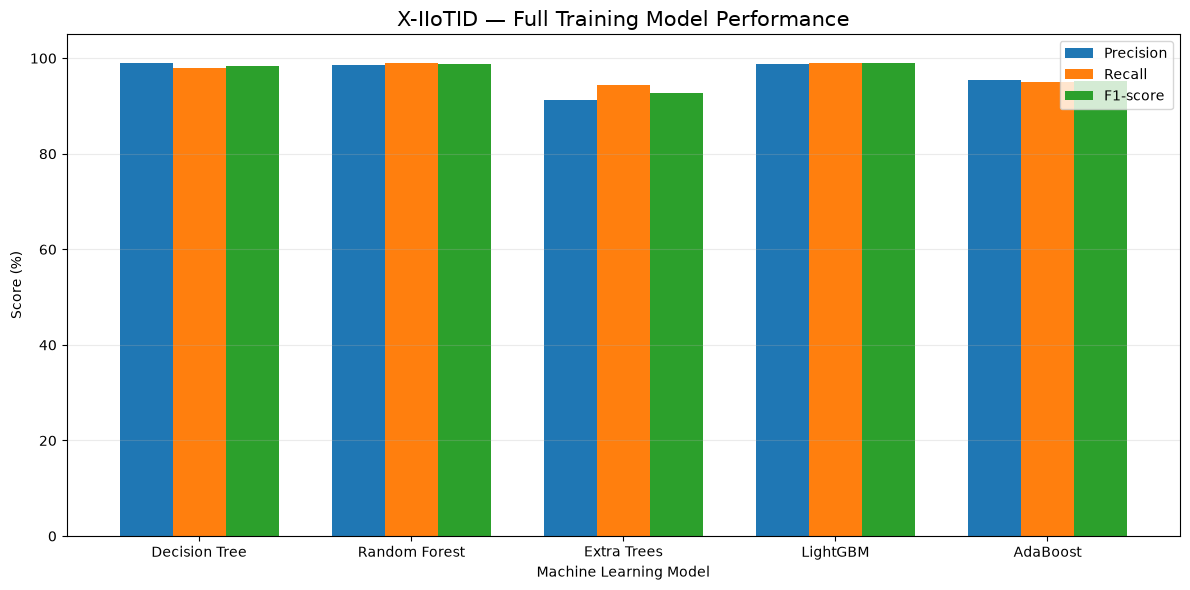

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_full_training_model_performance.png


In [4]:
import matplotlib.pyplot as plt
import pandas as pd

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

names = {
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "extra_trees": "Extra Trees",
    "lightgbm": "LightGBM",
    "adaboost": "AdaBoost",
}

df = res.copy()

df["model_name"] = df["model"].map(names)
df["precision_pct"] = df["precision_attack"] * 100
df["recall_pct"] = df["recall_attack"] * 100
df["f1_pct"] = df["f1_attack"] * 100

df = df.set_index("model_name")

ax = df[
    ["precision_pct", "recall_pct", "f1_pct"]
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "X-IIoTID — Full Training Model Performance",
    fontsize=15
)

ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

ax.legend([
    "Precision",
    "Recall",
    "F1-score"
])

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIGURES / (
    "x_iiotid_full_training_model_performance.png"
)

plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)

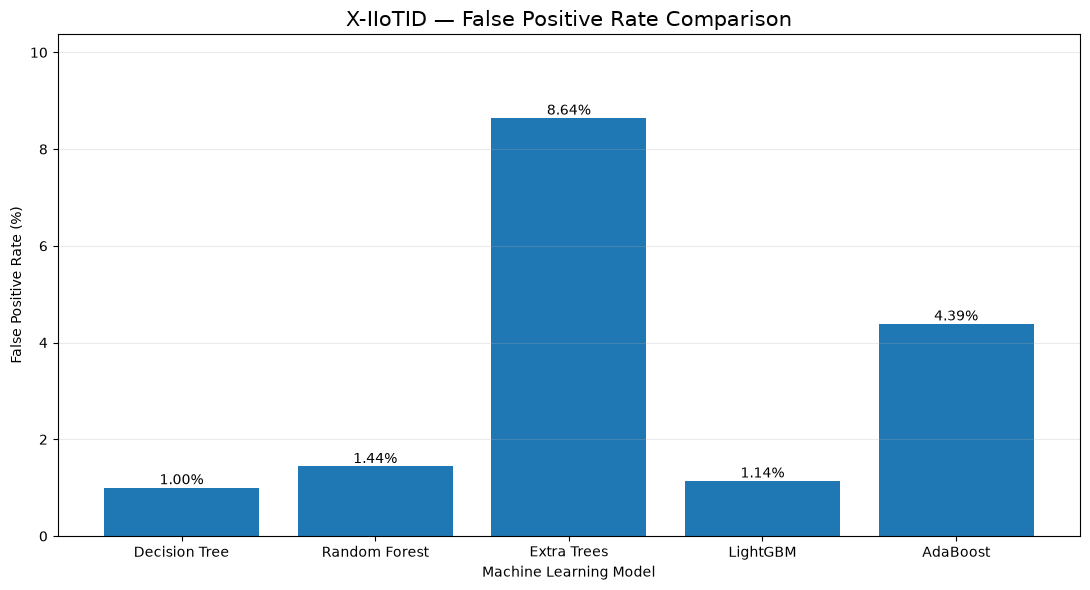

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_full_training_false_positive_comparison.png


In [5]:
fig, ax = plt.subplots(figsize=(11, 6))

fpr = df["false_positive_rate"] * 100

bars = ax.bar(
    fpr.index,
    fpr.values
)

ax.set_title(
    "X-IIoTID — False Positive Rate Comparison",
    fontsize=15
)

ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("False Positive Rate (%)")

ax.set_ylim(0, max(fpr.values) * 1.2)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIGURES / (
    "x_iiotid_full_training_false_positive_comparison.png"
)

plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)

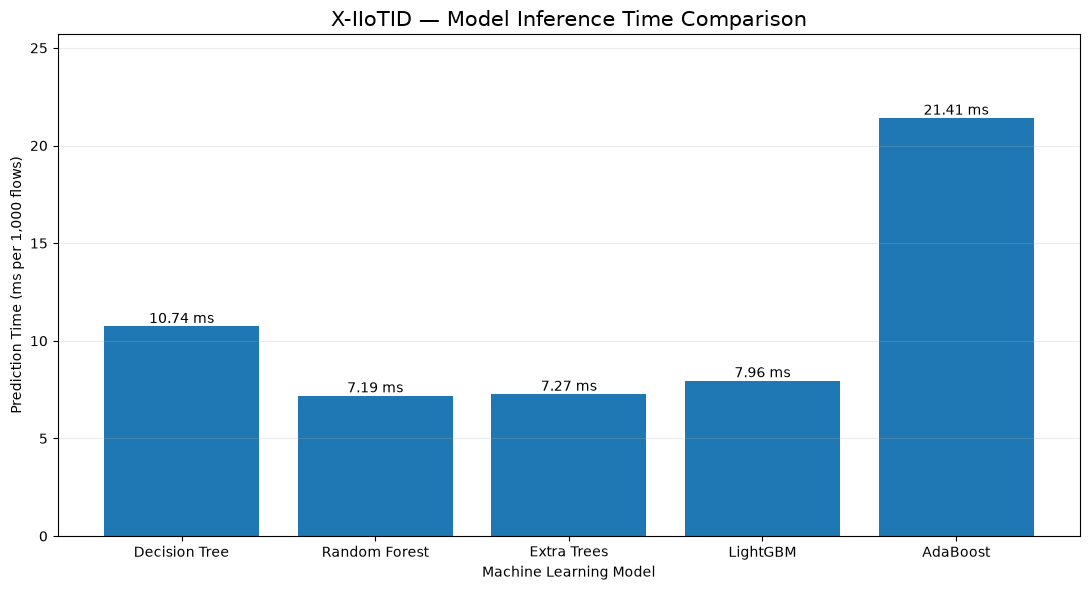

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_full_training_inference_comparison.png


In [6]:
fig, ax = plt.subplots(figsize=(11, 6))

speed = df["predict_ms_per_1000"]

bars = ax.bar(
    speed.index,
    speed.values
)

ax.set_title(
    "X-IIoTID — Model Inference Time Comparison",
    fontsize=15
)

ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Prediction Time (ms per 1,000 flows)")

ax.set_ylim(0, max(speed.values) * 1.2)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f} ms",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIGURES / (
    "x_iiotid_full_training_inference_comparison.png"
)

plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)

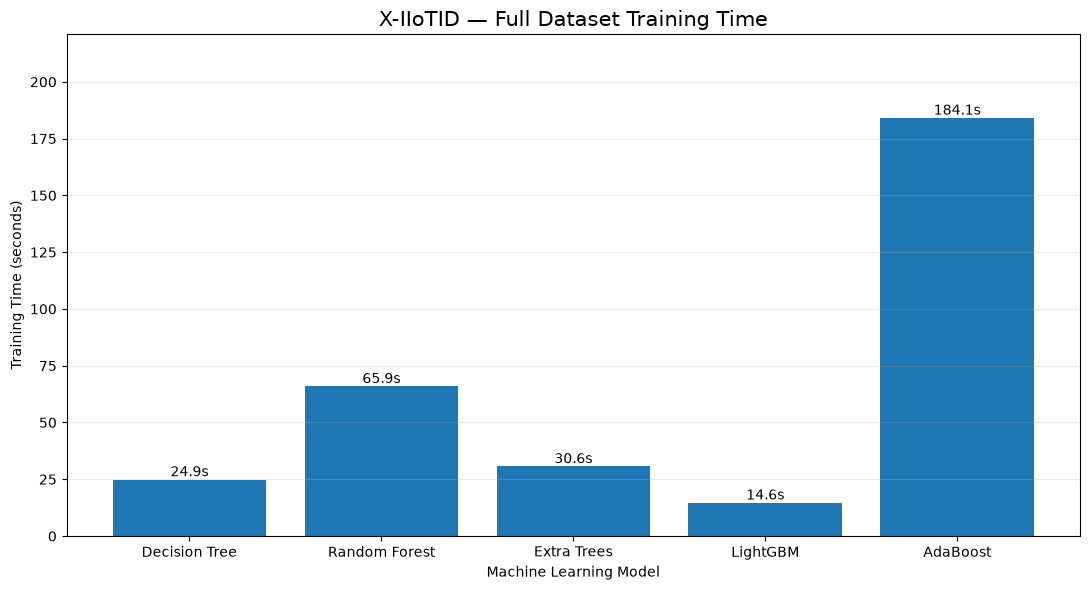

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_full_training_training_time.png


In [7]:
fig, ax = plt.subplots(figsize=(11, 6))

train_time = df["fit_seconds"]

bars = ax.bar(
    train_time.index,
    train_time.values
)

ax.set_title(
    "X-IIoTID — Full Dataset Training Time",
    fontsize=15
)

ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Training Time (seconds)")

ax.set_ylim(0, max(train_time.values) * 1.2)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}s",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIGURES / (
    "x_iiotid_full_training_training_time.png"
)

plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)

In [8]:
REPORTS = ROOT / "reports" / "audits"

output = REPORTS / (
    "x_iiotid_full_training_five_model_comparison.csv"
)

res.to_csv(output, index=False)

print("Comparison table saved:", output)

print("\nTraining row verification:")
print(res[[
    "model",
    "train_rows_used",
    "validation_rows",
    "test_evaluated"
]].to_string(index=False))

print("\nAll use full training:",
      (res["train_rows_used"] == 574585).all())

print("Same frozen split:",
      res["frozen_manifest_sha256"].nunique() == 1)

print("Test untouched:",
      (~res["test_evaluated"].astype(bool)).all())

Comparison table saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_full_training_five_model_comparison.csv

Training row verification:
        model  train_rows_used  validation_rows  test_evaluated
decision_tree           574585           123125           False
random_forest           574585           123125           False
  extra_trees           574585           123125           False
     lightgbm           574585           123125           False
     adaboost           574585           123125           False

All use full training: True
Same frozen split: True
Test untouched: True


**Interpretation:** Compare F1/recall and false-positive rate alongside laptop inference time. Selecting a model by validation performance is acceptable, but final **test data must remain unseen** until model/ensemble selection is fixed. Time measured on this computer is not representative of Raspberry Pi.
